In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

import os
FIGDIR = "results/eda_visualizations"
os.makedirs(FIGDIR, exist_ok=True)

GLU = pd.read_csv("results/outputs/diabetes_glucose.csv")
print("loaded:", GLU.shape)
GLU.head()

loaded: (13511, 31)


,patient_id,timestamp,date,time,hour,time_of_day,day_of_week,is_weekend,reading_index,code,context,code_description,glucose_mg_dl,prev_glucose,prev_glucose_2,glucose_change,hours_since_prev,hours_to_next,rolling_mean_3,rolling_std_3,insulin_regular_6h,insulin_nph_6h,insulin_ultralente_6h,total_insulin_6h,daily_total_insulin,meals_6h,exercise_6h,hypo_symptoms_6h,risk_class,next_glucose,next_risk_class
0,1,1991-04-21 09:09:00,1991-04-21,09:09,9,morning,Sunday,True,1,58,pre_breakfast,Pre-breakfast blood glucose,100.0,NaN,NaN,NaN,NaN,7.983333,100.000000,NaN,9.0,13.0,0.0,22.0,29.0,0,0,0,Normal,119.0,Normal
1,1,1991-04-21 17:08:00,1991-04-21,17:08,17,afternoon,Sunday,True,2,62,pre_supper,Pre-supper blood glucose,119.0,100.0,NaN,19.0,7.983333,5.716667,109.500000,13.435029,7.0,0.0,0.0,7.0,29.0,0,0,0,Normal,123.0,Normal
2,1,1991-04-21 22:51:00,1991-04-21,22:51,22,night_late,Sunday,True,3,48,unspecified,Unspecified blood glucose measurement,123.0,119.0,100.0,4.0,5.716667,8.733333,114.000000,12.288206,7.0,0.0,0.0,7.0,29.0,0,0,0,Normal,216.0,Hyperglycemic
3,1,1991-04-22 07:35:00,1991-04-22,07:35,7,morning,Monday,False,4,58,pre_breakfast,Pre-breakfast blood glucose,216.0,123.0,119.0,93.0,8.733333,9.350000,152.666667,54.884728,10.0,13.0,0.0,23.0,32.0,0,0,0,Hyperglycemic,211.0,Hyperglycemic
4,1,1991-04-22 16:56:00,1991-04-22,16:56,16,afternoon,Monday,False,5,62,pre_supper,Pre-supper blood glucose,211.0,216.0,123.0,-5.0,9.350000,14.483333,183.333333,52.309974,9.0,0.0,0.0,9.0,32.0,0,0,0,Hyperglycemic,257.0,Hyperglycemic


In [2]:
GLU_clean = GLU.dropna(subset=["prev_glucose", "next_glucose"])\
               .drop(columns=["prev_glucose_2"]).copy()
GLU_out = GLU_clean[GLU_clean.hours_since_prev <= 48].copy()
num = GLU_out.select_dtypes(include=[np.number]).drop(
        columns=["patient_id", "code"], errors="ignore")
corr = num.corr()
print("numeric features:", num.shape[1])

numeric features: 18


In [3]:
rows = ["rolling_mean_3", "glucose_change", "prev_glucose",
        "rolling_std_3", "daily_total_insulin", "insulin_regular_6h"]

comparison = pd.DataFrame({
    "vs current (glucose_mg_dl)": corr["glucose_mg_dl"],
    "vs next (next_glucose)":     corr["next_glucose"],
}).loc[rows].round(3)
comparison["drop"] = (comparison.iloc[:,0].abs() - comparison.iloc[:,1].abs()).round(3)
print(comparison)

                     vs current (glucose_mg_dl)  vs next (next_glucose)   drop
rolling_mean_3                            0.663                   0.253  0.410
glucose_change                            0.638                   0.034  0.604
prev_glucose                              0.185                   0.144  0.041
rolling_std_3                             0.268                   0.157  0.111
daily_total_insulin                       0.228                   0.214  0.014
insulin_regular_6h                        0.171                   0.146  0.025


In [4]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high = [(a, b, round(upper.loc[a, b], 3))
        for a in upper.index for b in upper.columns
        if pd.notna(upper.loc[a, b]) and abs(upper.loc[a, b]) > 0.8]

print("feature pairs correlating above 0.8:")
for a, b, r in sorted(high, key=lambda x: -abs(x[2])):
    print(f"  {r:6.3f}   {a}  <->  {b}")

feature pairs correlating above 0.8:


### Why the >0.8 threshold above isn't the full picture

The pairwise check just above found **no pairs above 0.8**, which might suggest
there's nothing to remove. But a correlation coefficient only catches *linear
association* — it misses **exact structural redundancy**, i.e. a column that
is a deterministic formula of other columns already in the dataset. Two
columns here are like that:

- `glucose_change` is literally `glucose_mg_dl − prev_glucose`
- `total_insulin_6h` is literally `insulin_regular_6h + insulin_nph_6h + insulin_ultralente_6h`

Both parent columns are already kept as separate features, so these two add
**zero new information** — any model using the parents already has access to
exactly what these columns encode. That's confirmed directly below rather than
inferred from a correlation threshold.

In [5]:
reconstructed_change = GLU_out["glucose_mg_dl"] - GLU_out["prev_glucose"]
r1 = np.corrcoef(GLU_out["glucose_change"], reconstructed_change)[0, 1]
diff1 = (GLU_out["glucose_change"] - reconstructed_change).abs().max()

reconstructed_total = (GLU_out["insulin_regular_6h"] + GLU_out["insulin_nph_6h"]
                        + GLU_out["insulin_ultralente_6h"])
r2 = np.corrcoef(GLU_out["total_insulin_6h"], reconstructed_total)[0, 1]
diff2 = (GLU_out["total_insulin_6h"] - reconstructed_total).abs().max()

print(f"glucose_change vs (glucose_mg_dl - prev_glucose):  r = {r1:.6f}   max |diff| = {diff1:.6f}")
print(f"total_insulin_6h vs sum(insulin components):       r = {r2:.6f}   max |diff| = {diff2:.6f}")
print("\nBoth are exact (r = 1.0, zero deviation) -> safe to drop with no information loss.")

glucose_change vs (glucose_mg_dl - prev_glucose):  r = 1.000000   max |diff| = 0.000000
total_insulin_6h vs sum(insulin components):       r = 1.000000   max |diff| = 0.000000

Both are exact (r = 1.0, zero deviation) -> safe to drop with no information loss.


In [6]:
GLU_selected = GLU_out.drop(columns=["glucose_change", "total_insulin_6h"])

print("columns before feature selection:", GLU_out.shape[1])
print("columns after feature selection: ", GLU_selected.shape[1])
print("dropped:", [c for c in GLU_out.columns if c not in GLU_selected.columns])

columns before feature selection: 30
columns after feature selection:  28
dropped: ['glucose_change', 'total_insulin_6h']


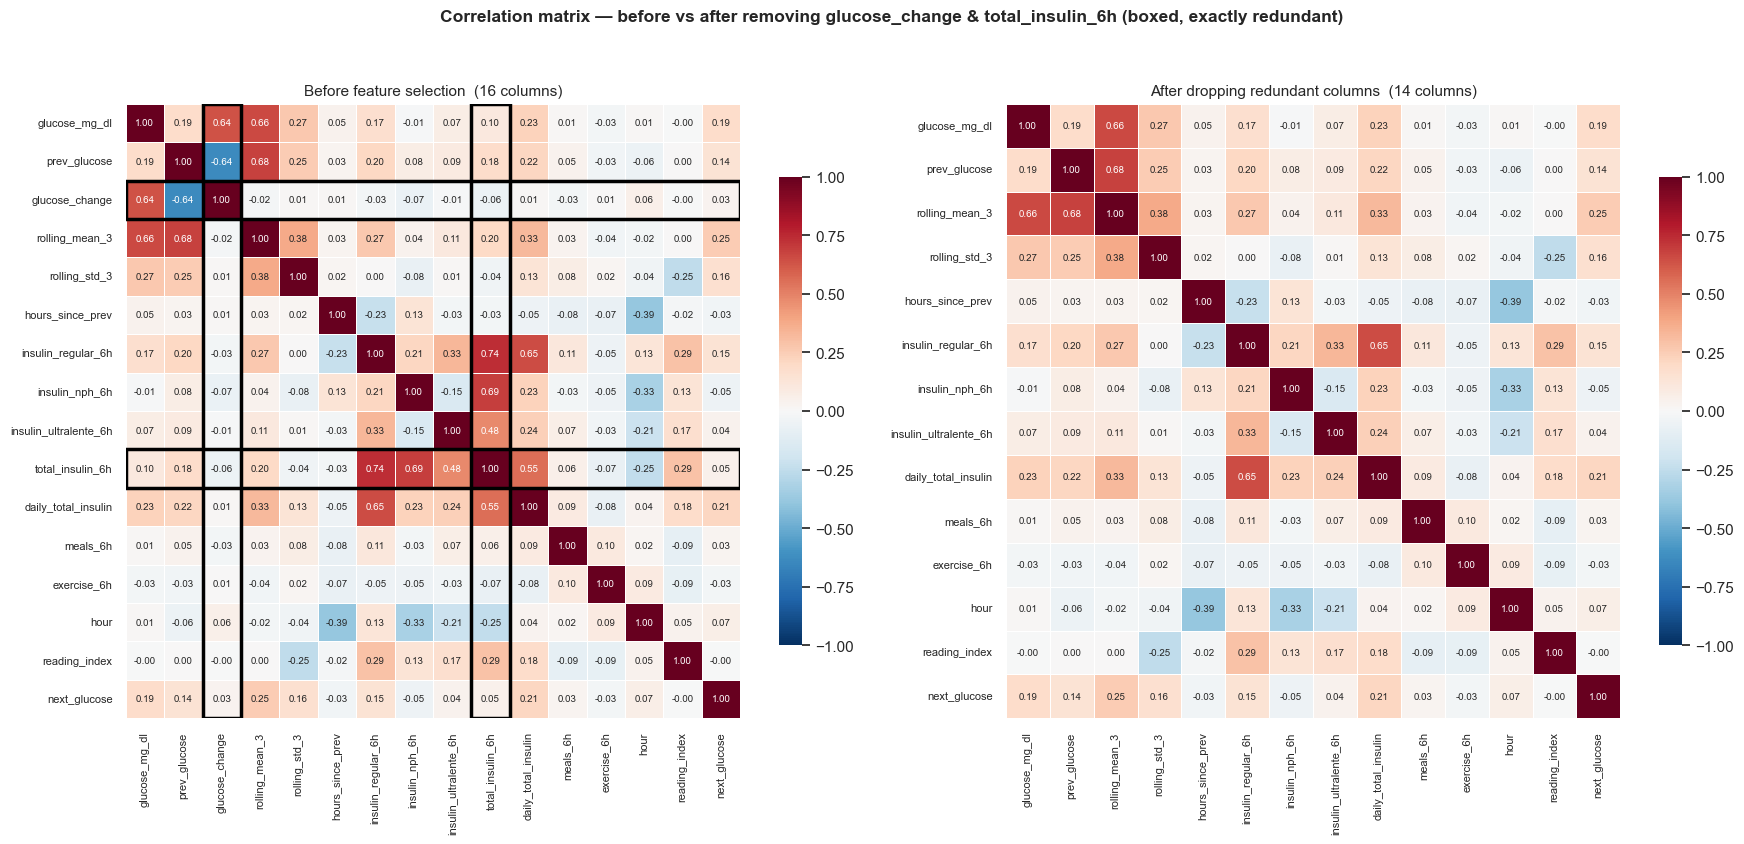

In [7]:
FEATURES_BEFORE = [
    "glucose_mg_dl", "prev_glucose", "glucose_change",
    "rolling_mean_3", "rolling_std_3", "hours_since_prev",
    "insulin_regular_6h", "insulin_nph_6h", "insulin_ultralente_6h",
    "total_insulin_6h", "daily_total_insulin",
    "meals_6h", "exercise_6h",
    "hour", "reading_index", "next_glucose",
]
FEATURES_AFTER = [c for c in FEATURES_BEFORE if c not in ["glucose_change", "total_insulin_6h"]]

corr_before = GLU_out[FEATURES_BEFORE].corr()
corr_after = GLU_selected[FEATURES_AFTER].corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
sns.heatmap(corr_before, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, linecolor="white", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.7}, ax=axes[0])
axes[0].set_title(f"Before feature selection  ({len(FEATURES_BEFORE)} columns)", fontsize=11)
axes[0].tick_params(axis="x", rotation=90, labelsize=8)
axes[0].tick_params(axis="y", rotation=0, labelsize=8)
for lbl in ["glucose_change", "total_insulin_6h"]:
    i = FEATURES_BEFORE.index(lbl)
    axes[0].add_patch(plt.Rectangle((i, 0), 1, len(FEATURES_BEFORE), fill=False, edgecolor="black", lw=2.5))
    axes[0].add_patch(plt.Rectangle((0, i), len(FEATURES_BEFORE), 1, fill=False, edgecolor="black", lw=2.5))

sns.heatmap(corr_after, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, linecolor="white", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.7}, ax=axes[1])
axes[1].set_title(f"After dropping redundant columns  ({len(FEATURES_AFTER)} columns)", fontsize=11)
axes[1].tick_params(axis="x", rotation=90, labelsize=8)
axes[1].tick_params(axis="y", rotation=0, labelsize=8)

fig.suptitle("Correlation matrix — before vs after removing glucose_change & total_insulin_6h (boxed, exactly redundant)",
             fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/feature_selection_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation

The boxed row/column in the "before" panel highlights exactly what's being
removed: `glucose_change` is strongly correlated with both `glucose_mg_dl`
(0.64) and `prev_glucose` (−0.64) because it's built from them, and
`total_insulin_6h` correlates with all three insulin-type columns (0.74,
0.69, 0.48) for the same reason. In the "after" panel both rows/columns are
simply gone — the remaining 14 predictor columns (excluding `next_glucose`)
each carry distinct information, none of it a deterministic function of
another column already present.

## Dimension reduction: PCA

The correlation check above shows the remaining features aren't linearly
redundant with each other, but PCA can still reveal whether they share
underlying structure that could be compressed into fewer dimensions.

**Important preprocessing fix:** PCA maximizes variance, so it must run on
**standardized** features — otherwise a large-magnitude column like
`daily_total_insulin` would dominate the components purely because of its raw
scale, not because it's more informative. `glucose_mg_dl` and `next_glucose`
are excluded from the PCA input (kept aside as the current reading and
target), and `patient_id`/`code` are identifiers, not features.

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

num = GLU_selected.select_dtypes(include=[np.number]).drop(columns=["patient_id", "code"], errors="ignore")
feature_cols = [c for c in num.columns if c not in ["next_glucose", "glucose_mg_dl"]]
print("PCA input features:", len(feature_cols))

X = GLU_selected[feature_cols].fillna(0)
X_scaled = StandardScaler().fit_transform(X)

pca = PCA()
pca.fit(X_scaled)
cum = np.cumsum(pca.explained_variance_ratio_)

for i, v in enumerate(cum, 1):
    print(f"{i:2d} components: {v*100:5.1f}% of variance explained")

N_COMPONENTS = int(np.argmax(cum >= 0.95) + 1)
print(f"\ncomponents needed for 95%: {N_COMPONENTS} of {len(feature_cols)}")

PCA input features: 14
 1 components:  17.8% of variance explained
 2 components:  30.1% of variance explained
 3 components:  41.8% of variance explained
 4 components:  50.5% of variance explained
 5 components:  58.5% of variance explained
 6 components:  65.4% of variance explained
 7 components:  72.1% of variance explained
 8 components:  78.5% of variance explained
 9 components:  84.2% of variance explained
10 components:  89.1% of variance explained
11 components:  93.4% of variance explained
12 components:  95.9% of variance explained
13 components:  98.0% of variance explained
14 components: 100.0% of variance explained

components needed for 95%: 12 of 14


### An honest reading of this result

12 of 14 components are needed to reach 95% variance — barely any
compression. That is itself a meaningful, defensible conclusion rather than a
failed attempt: it confirms what the correlation matrix already showed, that
these 14 features (rolling statistics, the three insulin types, timing,
meals/exercise/hypo flags) each capture largely **independent** information.
PCA is most useful when features are highly correlated; here it demonstrates
the opposite — the feature-selection step already removed the actual
redundancy, and what's left is genuinely non-redundant. Rather than force an
aggressive reduction that would discard information for little compression
benefit, the components needed for 95% variance (12) are kept, which still
removes 2 dimensions while preserving virtually all of the information.

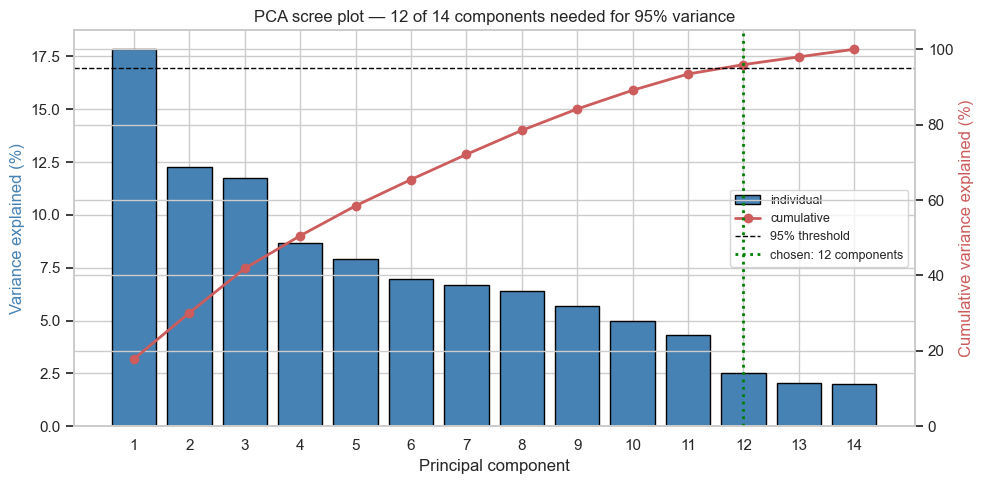

In [9]:
fig, ax1 = plt.subplots(figsize=(10, 5))
comps = np.arange(1, len(feature_cols) + 1)
ax1.bar(comps, pca.explained_variance_ratio_ * 100, color="steelblue", edgecolor="black", label="individual")
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Variance explained (%)", color="steelblue")
ax1.set_xticks(comps)

ax2 = ax1.twinx()
ax2.plot(comps, cum * 100, color="indianred", marker="o", lw=2, label="cumulative")
ax2.axhline(95, color="black", linestyle="--", lw=1, label="95% threshold")
ax2.axvline(N_COMPONENTS, color="green", linestyle=":", lw=2, label=f"chosen: {N_COMPONENTS} components")
ax2.set_ylabel("Cumulative variance explained (%)", color="indianred")
ax2.set_ylim(0, 105)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right", fontsize=9)

plt.title(f"PCA scree plot — {N_COMPONENTS} of {len(feature_cols)} components needed for 95% variance")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/pca_scree_plot.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
pca_final = PCA(n_components=N_COMPONENTS)
pcs = pca_final.fit_transform(X_scaled)
pc_cols = [f"PC{i+1}" for i in range(N_COMPONENTS)]

GLU_final = GLU_selected.reset_index(drop=True).copy()
for i, col in enumerate(pc_cols):
    GLU_final[col] = pcs[:, i]

print("shape before PCA columns added:", GLU_selected.shape)
print("shape after:                   ", GLU_final.shape)
print("new columns:", pc_cols)

shape before PCA columns added: (13294, 28)
shape after:                    (13294, 40)
new columns: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12']


In [11]:
GLU_final.to_csv("results/outputs/05_features_selected.csv", index=False)
print("saved:", GLU_final.shape)

saved: (13294, 40)
